# Let's Fill the Cart!

An exploratory analysis of grocery orders from Instacart, covering data preprocessing and the shopping habits of its customers.

## Contents

* Introduction
    * Data dictionary
* Step 1. Data overview
* Step 2. Data preprocessing
    * Duplicates
    * Missing values
* Step 3. Data analysis
    * A. Easy
    * B. Medium
    * C. Hard
* General conclusion

## Introduction

Instacart is a grocery delivery platform where customers can place an order at a supermarket and then receive their purchase, similar to how Uber Eats and iFood work. The dataset was modified from the original: its size was reduced so that calculations run faster, and missing values and duplicates were added. The distributions of the original data were preserved when the changes were made.

The project has three steps: a data overview, data preprocessing and an exploratory data analysis (EDA). Each step starts with a short introduction of how it is carried out, and the decisions are justified as the work progresses. A general conclusion summarizes the findings and the choices made.

### Data dictionary

There are five tables in the dataset, and all of them are used to preprocess the data and to run the EDA. Below is a dictionary that lists the columns of each table and describes the data they contain.

* `instacart_orders.csv`: each row corresponds to an order in the Instacart app
    * `order_id`: unique number that identifies each order
    * `user_id`: unique identification number of each customer account
    * `order_number`: number of times the customer has placed an order
    * `order_dow`: day of the week on which the order was placed (0 is Sunday)
    * `order_hour_of_day`: hour of the day at which the order was placed
    * `days_since_prior_order`: number of days since the customer placed their previous order

* `products.csv`: each row corresponds to a unique product that customers can buy
    * `product_id`: unique identification number of each product
    * `product_name`: name of the product
    * `aisle_id`: unique identification number of each grocery aisle category
    * `department_id`: unique identification number of each grocery department category

* `order_products.csv`: each row corresponds to an item included in an order
    * `order_id`: unique number that identifies each order
    * `product_id`: unique identification number of each product
    * `add_to_cart_order`: sequential order in which each item was added to the cart
    * `reordered`: 0 if the customer had never bought the product before, 1 if they had

* `aisles.csv`
    * `aisle_id`: unique identification number of each grocery aisle category
    * `aisle`: name of the aisle

* `departments.csv`
    * `department_id`: unique identification number of each grocery department category
    * `department`: name of the department

## Step 1. Data overview

We read the five data files with `pd.read_csv()` and inspect each DataFrame.

### Solution plan

1. Open the files to understand how they are stored (here, all of them use `;` as the separator) and read them with the right parameters.
2. Call `info()` and `sample()` on each DataFrame to see the data types, the missing values and what the values look like.
3. Use these first observations to plan the cleaning in Step 2.

In [1]:
import pandas as pd
from matplotlib import pyplot as plt

In [2]:
# Read the datasets into DataFrames
df_instacart_orders = pd.read_csv('dataframes/instacart_orders.csv', sep=';')
df_products = pd.read_csv('dataframes/products.csv', sep=';')
df_aisles = pd.read_csv('dataframes/aisles.csv', sep=';')
df_departments = pd.read_csv('dataframes/departments.csv', sep=';')
df_order_products = pd.read_csv('dataframes/order_products.zip', sep=';')  # zipped to keep the repository light

In [3]:
df_instacart_orders.info()
print()
print(df_instacart_orders.sample(5, random_state=42))

<class 'pandas.DataFrame'>
RangeIndex: 478967 entries, 0 to 478966
Data columns (total 6 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   order_id                478967 non-null  int64  
 1   user_id                 478967 non-null  int64  
 2   order_number            478967 non-null  int64  
 3   order_dow               478967 non-null  int64  
 4   order_hour_of_day       478967 non-null  int64  
 5   days_since_prior_order  450148 non-null  float64
dtypes: float64(1), int64(5)
memory usage: 21.9 MB

        order_id  user_id  order_number  order_dow  order_hour_of_day  \
478011    187515    84759             1          2                 15   
176737     14154   184924            41          2                 15   
402189   1978043   151955            21          1                 23   
111658   2907266    43250            11          1                  8   
59935    3245658   115414             5          2  

In [4]:
df_products.info()
print()
print(df_products.sample(5, random_state=42))

<class 'pandas.DataFrame'>
RangeIndex: 49694 entries, 0 to 49693
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   product_id     49694 non-null  int64
 1   product_name   48436 non-null  str  
 2   aisle_id       49694 non-null  int64
 3   department_id  49694 non-null  int64
dtypes: int64(3), str(1)
memory usage: 1.5 MB

       product_id                                   product_name  aisle_id  \
11902       11903                               Beef Chuck Roast         6   
4162         4163                         Spanish Rice Pilaf Mix         4   
17736       17737    Gluten Free Red Velvet & Tuxedo Cupcake Duo         8   
46680       46681  Organic Icelandic- Whole Milk- Vanilla Yogurt       120   
38823       38824                       Deli Sliced Swiss Cheese        21   

       department_id  
11902              2  
4162               9  
17736              3  
46680             16  
38823             16

In [5]:
df_aisles.info()
print()
print(df_aisles.sample(5, random_state=42))

<class 'pandas.DataFrame'>
RangeIndex: 134 entries, 0 to 133
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   aisle_id  134 non-null    int64
 1   aisle     134 non-null    str  
dtypes: int64(1), str(1)
memory usage: 2.2 KB

     aisle_id                       aisle
127       128        tortillas flat bread
66         67        fresh dips tapenades
104       105  doughs gelatins bake mixes
19         20                oral hygiene
42         43                  buns rolls


In [6]:
df_departments.info()
print()
print(df_departments.sample(5, random_state=42))

<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   department_id  21 non-null     int64
 1   department     21 non-null     str  
dtypes: int64(1), str(1)
memory usage: 468.0 bytes

    department_id       department
0               1           frozen
17             18           babies
15             16       dairy eggs
1               2            other
8               9  dry goods pasta


In [7]:
df_order_products.info(show_counts=True)
print()
print(df_order_products.sample(5, random_state=42))

<class 'pandas.DataFrame'>
RangeIndex: 4545007 entries, 0 to 4545006
Data columns (total 4 columns):
 #   Column             Non-Null Count    Dtype  
---  ------             --------------    -----  
 0   order_id           4545007 non-null  int64  
 1   product_id         4545007 non-null  int64  
 2   add_to_cart_order  4544171 non-null  float64
 3   reordered          4545007 non-null  int64  
dtypes: float64(1), int64(3)
memory usage: 138.7 MB



         order_id  product_id  add_to_cart_order  reordered
1274557   2182877       36412                2.0          0
136271    1692632       49383               19.0          0
2327440   1054700       11520                9.0          1
1228514   2495519        9973                9.0          0
1462440   2330427       27845                3.0          1


### Conclusions

* Opening the files in a text editor showed that the separator is `;` in all of them, which is why `sep=';'` is used when reading them.
* `info()` shows that the ID columns (`order_id`, `product_id`, and so on) are already integers, which is the right type for identifiers and for joining tables, so they need no conversion.
* The same output shows where values are missing: `product_name` in `products`, `days_since_prior_order` in `instacart_orders` and `add_to_cart_order` in `order_products`. The last one is a `float` only because of its missing values.
* `df_order_products` has many rows, so `info(show_counts=True)` is used to display the non-null counts.
* `sample()` gives a quick idea of what the values look like, without opening the files one by one. Calling `info()` and `sample()` is a good way to start any analysis.

## Step 2. Data preprocessing

The preprocessing has three goals:

* Check and fix the data types (for example, make sure the ID columns are integers).
* Identify and fill missing values.
* Identify and remove duplicated values.

For each case we explain what we found, what we did about it and why.

### Solution plan

We look for duplicated rows and missing values in each table, fix the data types that need conversion (for example, a float column that can safely become an integer) and keep a record of why each decision was taken.

### Duplicates

#### DataFrame `instacart_orders`

In [8]:
print(df_instacart_orders.duplicated().sum())

15


Are there duplicated rows? If so, what do they have in common? We check all the orders placed at 2 a.m. on Wednesdays:

In [9]:
wednesday_2am = df_instacart_orders[(df_instacart_orders['order_hour_of_day'] == 2) & (df_instacart_orders['order_dow'] == 3)]

print('Orders placed on Wednesdays at 2 a.m.:', len(wednesday_2am))
print('Duplicated rows among them:', wednesday_2am.duplicated().sum())

Orders placed on Wednesdays at 2 a.m.: 121
Duplicated rows among them: 15


There are 121 orders placed on a Wednesday at 2 a.m., which is an unusual time for that many orders and raises suspicion. All of the duplicated orders found above were placed at that time, which confirms that the duplication is concentrated there. We remove them:

In [10]:
df_instacart_orders = df_instacart_orders.drop_duplicates().reset_index(drop=True)

In [11]:
print(df_instacart_orders.duplicated().sum())  # check for duplicated rows again

0


In [12]:
print(df_instacart_orders.duplicated(subset='order_id').sum())  # check only the duplicated order IDs
print()
print(df_instacart_orders['order_id'].value_counts())

0

order_id
1515936    1
1690866    1
1454967    1
1768857    1
3007858    1
          ..
3210681    1
3270802    1
885349     1
216274     1
2071924    1
Name: count, Length: 478952, dtype: int64


We applied `drop_duplicates()` followed by `reset_index(drop=True)` so that the index does not keep gaps, and confirmed that the duplicates are gone: no row is duplicated and every `order_id` appears exactly once.

It is still odd that so many orders were placed in the early hours of a Wednesday. Whatever the cause (a system bug is the most likely one), the duplicated rows were removed and the remaining orders are legitimate.

#### DataFrame `products`

In [13]:
print(df_products.duplicated().sum())  # fully duplicated rows

0


In [14]:
print(df_products['product_id'].duplicated().sum())  # duplicated product IDs only

0


In [15]:
df_products['product_name'] = df_products['product_name'].str.lower()
print(df_products['product_name'].duplicated().sum())  # duplicated product names (in lowercase, for a better comparison)

1361


In [16]:
print(df_products['product_name'].dropna().duplicated().sum())  # duplicated names that are not missing

print()

# keep=False shows every occurrence, not only the repeated ones
print(df_products[df_products['product_name'].duplicated(keep=False)][['product_id', 'product_name']].sort_values('product_name'))

104

       product_id                               product_name
23339       23340  18-in-1 hemp peppermint pure-castile soap
31844       31845  18-in-1 hemp peppermint pure-castile soap
19941       19942            aged balsamic vinegar of modena
13152       13153            aged balsamic vinegar of modena
24830       24831         albacore solid white tuna in water
...           ...                                        ...
49552       49553                                        NaN
49574       49575                                        NaN
49640       49641                                        NaN
49663       49664                                        NaN
49668       49669                                        NaN

[1465 rows x 2 columns]


We found a registration problem: the same product appears under more than one code. Looking at the names in lowercase makes it visible, because the capitalization of the names was not standardized before.

* Of the duplicated names, most are missing values (they are all `NaN`) and 104 are real product names registered with more than one ID.
* We used `keep=False` so that every occurrence is listed. By default pandas hides the first occurrence of each duplicate.
* We sorted by `product_name`, so that we see the duplicated names together and not the codes.

These duplicates can distort product counts, because the same product is split across several IDs. They are not removed here, since each ID is still a valid product in the catalog and the orders refer to those IDs.

#### DataFrame `departments`

In [17]:
print(df_departments.duplicated().sum())  # fully duplicated rows

0


In [18]:
print(df_departments['department_id'].duplicated().sum())  # duplicated department IDs

0


This table has no duplicates.

#### DataFrame `aisles`

In [19]:
print(df_aisles.duplicated().sum())  # fully duplicated rows

0


In [20]:
print(df_aisles['aisle_id'].duplicated().sum())  # duplicated aisle IDs

0


This table has no duplicates either.

#### DataFrame `order_products`

In [21]:
print(df_order_products.duplicated().sum())  # fully duplicated rows

0


In [22]:
# One more check for tricky duplicates
print(df_order_products['order_id'].duplicated().sum())
print(df_order_products['product_id'].duplicated().sum())

4094961


4499434


There are no fully duplicated rows. The repetitions in `order_id` and `product_id` are expected: an order has several products, and a product can be bought in several orders.

### Missing values

While handling duplicates we noticed missing values that we need to investigate in these columns:

* `product_name` in the `products` table
* `days_since_prior_order` in the `instacart_orders` table
* `add_to_cart_order` in the `order_products` table

#### DataFrame `products`

In [23]:
print(df_products[df_products['product_name'].isna()])  # missing values in 'product_name'

       product_id product_name  aisle_id  department_id
37             38          NaN       100             21
71             72          NaN       100             21
109           110          NaN       100             21
296           297          NaN       100             21
416           417          NaN       100             21
...           ...          ...       ...            ...
49552       49553          NaN       100             21
49574       49575          NaN       100             21
49640       49641          NaN       100             21
49663       49664          NaN       100             21
49668       49669          NaN       100             21

[1258 rows x 4 columns]


There are 1,258 products without a name in the database, which could compromise any future analysis that depends on this information. Are they all linked to aisle ID 100?

In [24]:
print(df_products['aisle_id'].value_counts())

aisle_id
100    1258
45     1246
37     1091
47     1038
120    1026
       ... 
113      47
82       44
32       32
68       26
18       12
Name: count, Length: 134, dtype: int64


Yes. All the missing product names belong to aisle 100: the 1,258 missing names match the number of times aisle 100 appears. Are they also all linked to department ID 21?

In [25]:
print(df_products['department_id'].value_counts())

department_id
11    6564
19    6264
13    5372
7     4366
1     4008
16    3449
17    3085
15    2092
9     1858
4     1684
3     1516
20    1322
21    1258
6     1139
14    1117
18    1081
5     1054
8      972
12     907
2      548
10      38
Name: count, dtype: int64


Yes again. All the missing product names belong to department 21, and the number of missing names matches the number of times department 21 appears. What do aisle 100 and department 21 represent?

In [26]:
print(df_aisles.query('aisle_id == 100')[['aisle_id', 'aisle']])
print()
print(df_departments.query('department_id == 21')[['department_id', 'department']])

    aisle_id    aisle
99       100  missing

    department_id department
20             21    missing


In both tables the aisle and the department are called `missing`: there is no information about that aisle and department in the database. The missing names are a registration gap, not random errors. We fill them with `'unknown'`:

In [27]:
df_products['product_name'] = df_products['product_name'].fillna('unknown')
print(df_products['product_name'].value_counts())

product_name
unknown                                       1258
green tea with ginseng and honey                 3
biotin 1000 mcg                                  2
fresh scent dishwasher detergent with dawn       2
american cheese slices                           2
                                              ... 
vodka- triple distilled- twist of vanilla        1
en croute roast hazelnut cranberry               1
artisan baguette                                 1
smartblend healthy metabolism dry cat food       1
fresh foaming cleanser                           1
Name: count, Length: 48333, dtype: int64


With the records marked as `unknown` instead of null, they keep being visible and traceable, and they are not silently ignored or left to distort counts and groupings.

#### DataFrame `instacart_orders`

In [28]:
print(df_instacart_orders.isna().sum())

order_id                      0
user_id                       0
order_number                  0
order_dow                     0
order_hour_of_day             0
days_since_prior_order    28817
dtype: int64


Are there missing values for customers who are not making their first order?

In [29]:
print(df_instacart_orders.query('order_number != 1').isna().sum())

order_id                  0
user_id                   0
order_number              0
order_dow                 0
order_hour_of_day         0
days_since_prior_order    0
dtype: int64


All the missing values in `days_since_prior_order` belong to first orders. A first order has no previous order to compare with, so these values are legitimate and cause no inconsistency. They are left as they are.

#### DataFrame `order_products`

In [30]:
print(df_order_products.isna().sum())

order_id               0
product_id             0
add_to_cart_order    836
reordered              0
dtype: int64


What are the minimum and maximum values of `add_to_cart_order`?

In [31]:
print(df_order_products['add_to_cart_order'].min())
print(df_order_products['add_to_cart_order'].max())

1.0
64.0


We save the IDs of all orders that have at least one missing value in `add_to_cart_order`:

In [32]:
cart_order_na = df_order_products[df_order_products['add_to_cart_order'].isna()]['order_id']
print(cart_order_na)

737        2449164
9926       1968313
14394      2926893
16418      1717990
30114      1959075
            ...   
4505662    1800005
4511400    1633337
4517562     404157
4534112    1673227
4535739    1832957
Name: order_id, Length: 836, dtype: int64


Do all the orders with missing values contain more than 64 products? We group the orders with missing data by order ID, count the `product_id` values in each one and look at the minimum count:

In [33]:
product_na = df_order_products[df_order_products['order_id'].isin(cart_order_na)].groupby('order_id')['product_id'].count()
print(product_na.min())

65


The minimum is 65 products. So whenever an order has more than 64 products, the system cannot record the position of the items after the 64th: the maximum value of the column is 64.

We replace the missing values with 999, a value outside the real range that works as a flag to identify these records easily in later analyses, and convert the column to an integer:

In [34]:
df_order_products['add_to_cart_order'] = df_order_products['add_to_cart_order'].fillna(999).astype('int')

df_order_products.info(show_counts=True)

<class 'pandas.DataFrame'>
RangeIndex: 4545007 entries, 0 to 4545006
Data columns (total 4 columns):
 #   Column             Non-Null Count    Dtype
---  ------             --------------    -----
 0   order_id           4545007 non-null  int64
 1   product_id         4545007 non-null  int64
 2   add_to_cart_order  4545007 non-null  int64
 3   reordered          4545007 non-null  int64
dtypes: int64(4)
memory usage: 138.7 MB


### Conclusions

During the preparation of the data we found three inconsistencies:

1. **Products without a name** in the `products` table. They all belong to the aisle and department called `missing`, and we filled them with `'unknown'` to keep them traceable.
2. **A system limitation** that prevents recording the position in the cart for orders with more than 64 products. We filled these cases with 999 and converted the column to an integer.
3. **Missing values in the days since the previous order.** They are not an error but the expected behavior for the first order of each customer, which naturally has no previous order to compare with.

We also removed 15 duplicated orders, all of them placed on Wednesday at 2 a.m., and found products that appear under more than one ID because of non-standardized names.

## Step 3. Data analysis

Once the data is processed and ready, we carry out the analysis in three levels of difficulty.

### A. Easy

1. Check that the values in the `order_hour_of_day` and `order_dow` columns of the `orders` table make sense (hours from 0 to 23, days of the week from 0 to 6).
2. Create a chart that shows how many people place orders at each hour of the day.
3. Create a chart that shows on which day of the week people shop.
4. Create a chart that shows how long people wait until their next order, and comment on the minimum and maximum values.

#### A1. Do the values make sense?

In [35]:
print(df_instacart_orders['order_hour_of_day'].min())
print(df_instacart_orders['order_hour_of_day'].max())

0
23


In [36]:
print(df_instacart_orders['order_dow'].min())
print(df_instacart_orders['order_dow'].max())

0
6


Both columns are within the expected ranges: hours go from 0 to 23 and days of the week from 0 to 6, so there is nothing to fix.

#### A2. How many people place orders at each hour of the day?

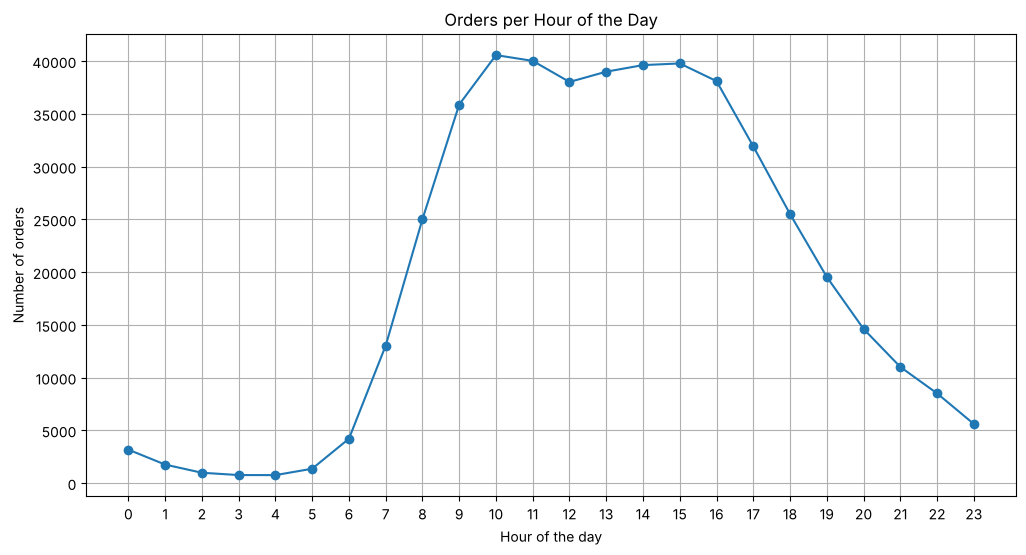

In [37]:
df_instacart_orders['order_hour_of_day'].value_counts().sort_index().plot(
    title='Orders per Hour of the Day',
    ylabel='Number of orders',
    xlabel='Hour of the day',
    grid=True,
    legend=False,
    kind='line',
    figsize=(12, 6),
    style='o-',
    xticks=range(0, 24, 1),
)
plt.show()

The peak of orders is at 10 a.m., and the volume stays high until 3 p.m., when it starts to fall. The lowest point is in the early hours of the morning, although many orders are still placed at 2 a.m.

#### A3. On which day of the week do people buy groceries?

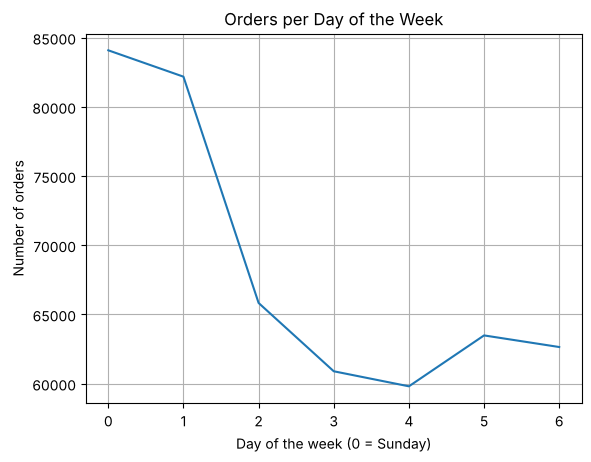

In [38]:
df_instacart_orders['order_dow'].value_counts().sort_index().plot(
    title='Orders per Day of the Week',
    ylabel='Number of orders',
    xlabel='Day of the week (0 = Sunday)',
    grid=True,
    legend=False,
    kind='line',
)
plt.show()

Most orders are placed on Sunday (0), and the lowest point is on Thursday (4).

#### A4. How long do people wait until they place another order?

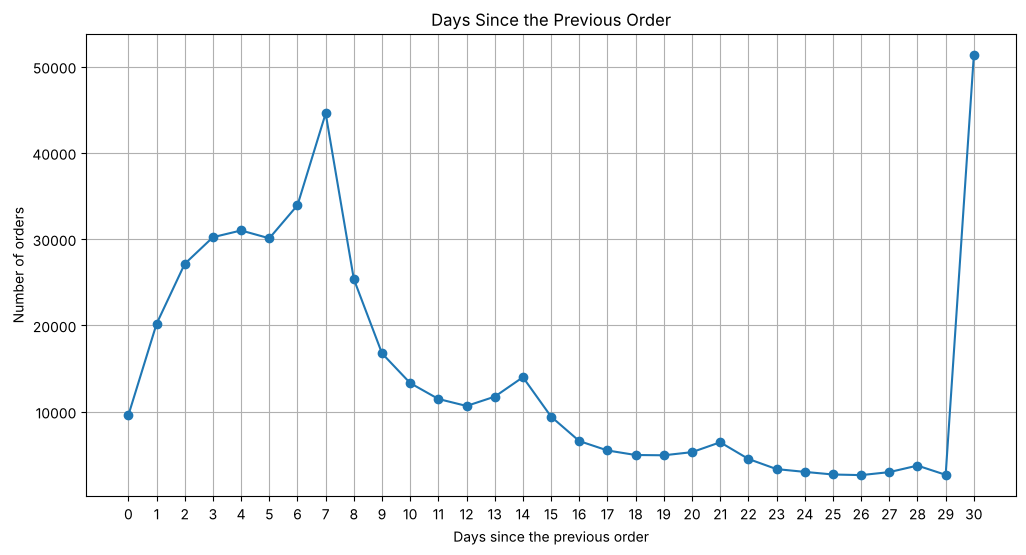

In [39]:
df_instacart_orders['days_since_prior_order'].value_counts().sort_index().plot(
    title='Days Since the Previous Order',
    ylabel='Number of orders',
    xlabel='Days since the previous order',
    grid=True,
    legend=False,
    kind='line',
    style='o-',
    figsize=(12, 6),
    xticks=range(0, 31, 1),
)
plt.show()

In [40]:
print(df_instacart_orders['days_since_prior_order'].min())
print(df_instacart_orders['days_since_prior_order'].max())
print()
print(df_instacart_orders['days_since_prior_order'].value_counts().sort_index().tail(3))

0.0
30.0

days_since_prior_order
28.0     3745
29.0     2673
30.0    51337
Name: count, dtype: int64


* The minimum is 0 days (the customer ordered again on the same day) and the maximum is 30 days.
* There are two peaks: the weekly shoppers (day 7) and the monthly shoppers (day 30). The lowest values are in the period between 25 and 29 days.
* The difference between the lowest point and the peak (day 29 against day 30) is large and can be explained by two hypotheses. The first is that many users make recurring monthly purchases, which concentrates orders exactly on day 30. The second is that the system may have a limit of 30 days and group all the customers who stayed longer than that without buying, which would inflate this value artificially and compromise the analysis.

### B. Medium

1. Is there any difference in the distribution of `order_hour_of_day` between Wednesdays and Saturdays? Build bar charts for both days in the same chart and describe the differences.
2. Build a distribution chart for the number of orders that customers place (how many customers placed only 1 order, how many placed only 2, and so on).
3. What are the 20 most frequently purchased products? Display their IDs and names.

#### B1. Differences between Wednesdays and Saturdays in `order_hour_of_day`

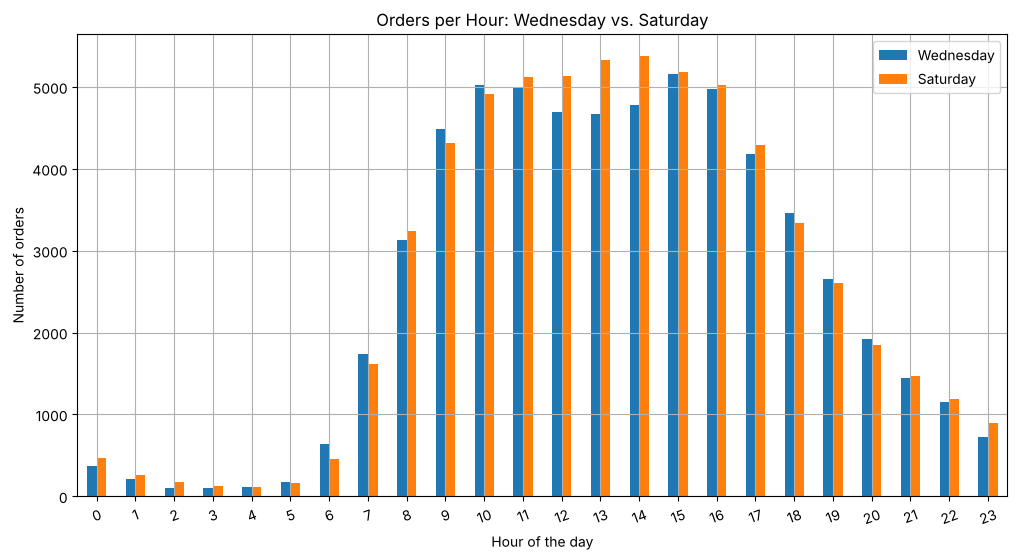

Hours in which Saturday has more orders than Wednesday: 16


In [41]:
wednesday_order_hour = df_instacart_orders.query('order_dow == 3')['order_hour_of_day'].value_counts().sort_index()
saturday_order_hour = df_instacart_orders.query('order_dow == 6')['order_hour_of_day'].value_counts().sort_index()

orders_by_hour = pd.DataFrame({
    'Wednesday': wednesday_order_hour,
    'Saturday': saturday_order_hour,
})

# The legend comes from the DataFrame columns, so it always matches the bars
orders_by_hour.plot(
    kind='bar',
    figsize=(12, 6),
    title='Orders per Hour: Wednesday vs. Saturday',
    ylabel='Number of orders',
    xlabel='Hour of the day',
    rot=20,
    grid=True,
)
plt.show()

print('Hours in which Saturday has more orders than Wednesday:', (orders_by_hour['Saturday'] > orders_by_hour['Wednesday']).sum())

The shape of both days is very similar, including the peaks and the lows. On Saturdays the peak is at 2 p.m., while on Wednesdays it is at 3 p.m., and even then it is lower than the number of Saturday orders at that same hour. Saturday also exceeds Wednesday in 16 of the 24 hours.

#### B2. What is the distribution of the number of orders per customer?

In [42]:
# Number of orders placed by each customer
orders_per_client = df_instacart_orders['user_id'].value_counts()

# Number of customers for each number of orders (how many customers made 1, 2, 3... orders)
client_distribution = orders_per_client.value_counts().sort_index()

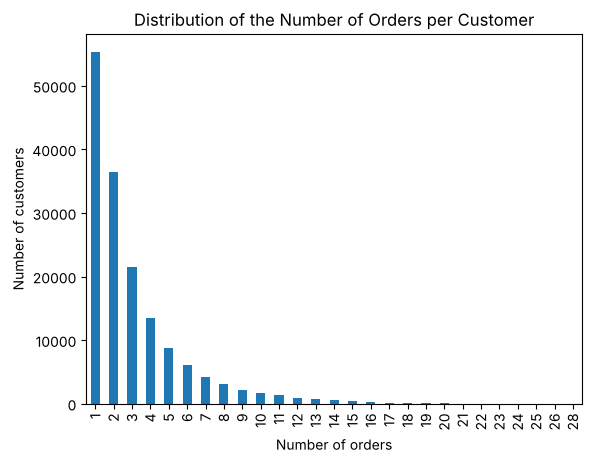

In [43]:
client_distribution.plot(
    kind='bar',
    title='Distribution of the Number of Orders per Customer',
    xlabel='Number of orders',
    ylabel='Number of customers',
)
plt.show()

Most customers placed only one order, more than twice as many as those who placed three. The chart almost disappears after the customers who placed 19 orders. This chart is a snapshot of the accumulated behavior and does not measure change over time, so it shows that most customers are not very recurrent, but it says nothing about whether the platform's popularity is growing or falling. That would require looking at the orders per period.

#### B3. What are the 20 most popular products? Display their IDs and names.

In [44]:
product_count = df_order_products['product_id'].value_counts()

# Turn the Series into a DataFrame so that it can be merged with the product names
df_product_count = product_count.reset_index()
df_product_count.columns = ['product_id', 'product_count']

In [45]:
# Join with df_products to bring in the product names
df_merged = df_product_count.merge(df_products, on='product_id')

In [46]:
# value_counts() already sorts in descending order, but sorting explicitly makes sure the ranking is right
df_merged = df_merged.sort_values('product_count', ascending=False)
print(df_merged[['product_id', 'product_name']].head(20))

    product_id              product_name
0        24852                    banana
1        13176    bag of organic bananas
2        21137      organic strawberries
3        21903      organic baby spinach
4        47209      organic hass avocado
5        47766           organic avocado
6        47626               large lemon
7        16797              strawberries
8        26209                     limes
9        27845        organic whole milk
10       27966       organic raspberries
11       22935      organic yellow onion
12       24964            organic garlic
13       45007          organic zucchini
14       39275       organic blueberries
15       49683            cucumber kirby
16       28204        organic fuji apple
17        5876             organic lemon
18        8277  apple honeycrisp organic
19       40706    organic grape tomatoes


The most popular products are fruits and fresh produce (bananas, strawberries, avocados, spinach, lemons). Put together with the previous results, this suggests a customer profile of people looking for healthier food. The behavior is concentrated from late morning to early afternoon, both on weekdays and on weekends, but it is not very recurrent, since most customers bought only a few times or just once on the platform.

### C. Hard

1. How many items do people usually buy in one order? What does the distribution look like?
2. What are the 20 items most frequently included in repeated orders? Display their IDs and names.
3. For each product, what share of its orders is repeated? Create a table with the product ID, the name and the proportion of repeated orders.
4. For each customer, what proportion of all their orders is repeated?
5. What are the 20 items that people put into their carts before all the others? Display the product ID, the name and the number of times it was the first item added to a cart.

#### C1. How many items do people usually buy in one order?

In [47]:
# How many 'product_id' values does each 'order_id' have?
order_count = df_order_products.groupby('order_id').count()['product_id'].value_counts().sort_index()

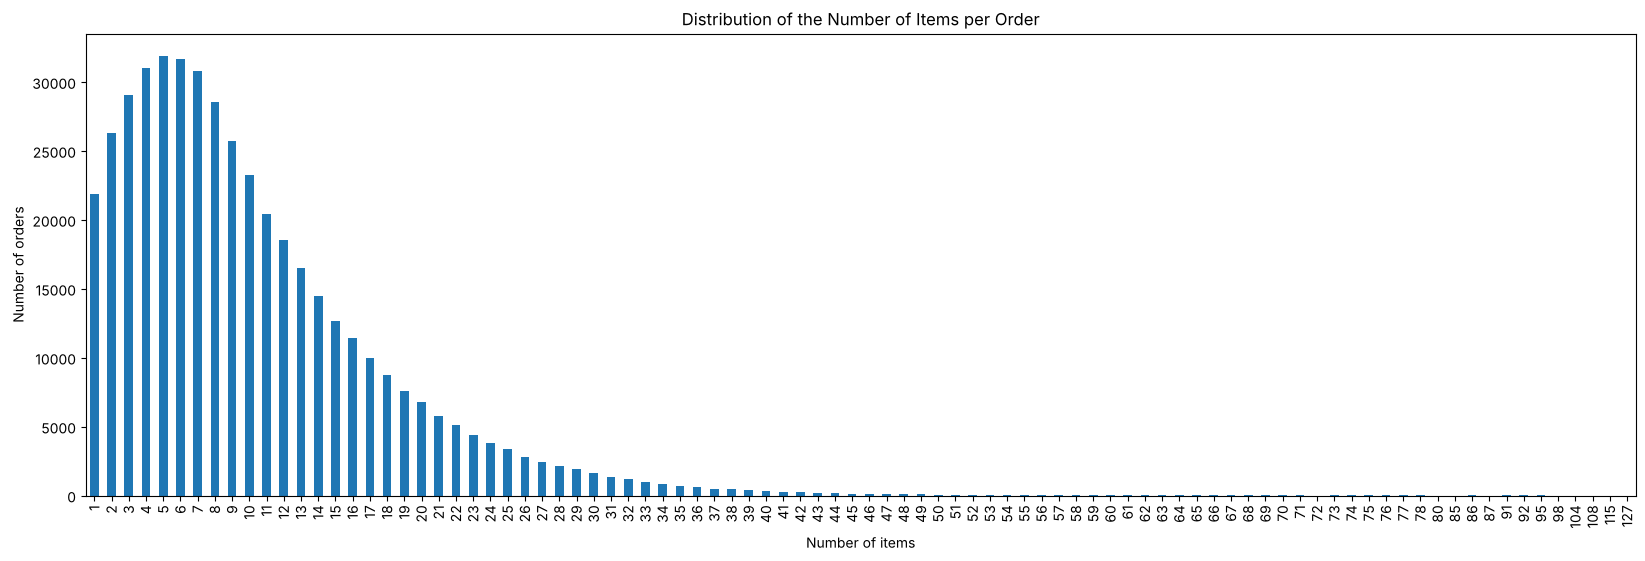

In [48]:
order_count.plot(
    kind='bar',
    title='Distribution of the Number of Items per Order',
    xlabel='Number of items',
    ylabel='Number of orders',
    figsize=(20, 6),
)
plt.show()

The chart shows that customers usually buy between 4 and 7 items at a time.

#### C2. What are the 20 items most frequently included in repeated orders?

In [49]:
# Keep only the products that were reordered
product_count = df_order_products.query('reordered == 1')['product_id'].value_counts()

In [50]:
df_product_count = product_count.reset_index()
df_product_count.columns = ['product_id', 'product_count']
print(df_product_count.head())

   product_id  product_count
0       24852          55763
1       13176          44450
2       21137          28639
3       21903          26233
4       47209          23629


In [51]:
df_merged = df_product_count.merge(df_products, on='product_id')

In [52]:
# Sort the products to get the top 20, from the highest to the lowest count
df_merged = df_merged.sort_values('product_count', ascending=False)
print(df_merged[['product_id', 'product_name']].head(20))

    product_id              product_name
0        24852                    banana
1        13176    bag of organic bananas
2        21137      organic strawberries
3        21903      organic baby spinach
4        47209      organic hass avocado
5        47766           organic avocado
6        27845        organic whole milk
7        47626               large lemon
8        27966       organic raspberries
9        16797              strawberries
10       26209                     limes
11       22935      organic yellow onion
12       24964            organic garlic
13       45007          organic zucchini
14       49683            cucumber kirby
15       28204        organic fuji apple
16        8277  apple honeycrisp organic
17       39275       organic blueberries
18        5876             organic lemon
19       49235       organic half & half


The most reordered items are practically the same as the ones in the top twenty of most popular products. They are recurring items that are part of the customers' basic consumption.

#### C3. For each product, what share of its orders is repeated?

In [53]:
# Reordered counts and total counts per product
reorder_count = df_order_products.query('reordered == 1')['product_id'].value_counts()
total_count = df_order_products['product_id'].value_counts()

# Name the index so that it can be used as the product_id column
reorder_count.index.name = 'product_id'
total_count.index.name = 'product_id'

df_reorder_share = pd.DataFrame({
    'reorder_count': reorder_count,
    'total_count': total_count,
})

df_reorder_share['reorder_share'] = df_reorder_share['reorder_count'] / df_reorder_share['total_count']

df_reorder_share = df_reorder_share.reset_index()
df_reorder_share = df_reorder_share.dropna(subset=['reorder_share'])

df_reorder_share = df_reorder_share.merge(df_products, on='product_id', how='inner')

# Sort the values for a better analysis
df_reorder_share = df_reorder_share.sort_values('reorder_share', ascending=False)

print(df_reorder_share[['product_id', 'product_name', 'reorder_share']])

       product_id                       product_name  reorder_share
36180       49625  golden wheat deep cleanse shampoo       1.000000
36176       49619                         opo squash       1.000000
36189       49639       pecans- maple- premium blend       1.000000
36161       49601            pomegranate gummy bears       1.000000
126           174     vanishing acne treatment cream       1.000000
...           ...                                ...            ...
34536       47385                     ground mustard       0.020833
27061       37120                          dill weed       0.018349
10643       14688                     bamboo skewers       0.018182
20937       28741              organic ground cloves       0.018182
32506       44626                    ground allspice       0.010989

[36228 rows x 3 columns]


The products with the highest reorder share are niche items, such as hygiene products or special food items like seasonings. They are rarely bought overall, so any reorder already represents a large fraction of the total, which artificially inflates the reorder percentage.

#### C4. For each customer, what proportion of all their orders is repeated?

In [54]:
# Merge the products of each order with the customer who placed it, then count the total items per customer
df_merged_orders = df_order_products.merge(df_instacart_orders[['order_id', 'user_id']], on='order_id')
total_items = df_merged_orders.groupby('user_id')['product_id'].count()

In [55]:
reorder_items = df_merged_orders[df_merged_orders['reordered'] == 1].groupby('user_id')['product_id'].count()

In [56]:
df_client_share = pd.DataFrame({
    'total_items': total_items,
    'reorder_items': reorder_items,
})

In [57]:
# Proportion of reordered items per customer
df_client_share['reorder_share'] = df_client_share['reorder_items'] / df_client_share['total_items']

df_client_share = df_client_share.sort_values('reorder_share', ascending=False)

print(df_client_share.dropna().reset_index())

        user_id  total_items  reorder_items  reorder_share
0        139383            1            1.0       1.000000
1         59928            9            9.0       1.000000
2         68147            4            4.0       1.000000
3         68175            3            3.0       1.000000
4        130234            1            1.0       1.000000
...         ...          ...            ...            ...
132986    19565           55            1.0       0.018182
132987    57630           57            1.0       0.017544
132988   155522           58            1.0       0.017241
132989   201663           66            1.0       0.015152
132990   106148           67            1.0       0.014925

[132991 rows x 4 columns]


The customers with the highest reorder rate, close to 100%, are usually the ones with very few items in total. These extreme values tend to come from a low volume and not necessarily from real loyalty. To trust this metric it is better to look only at customers with a minimum number of orders.

#### C5. What are the 20 items that people put into their carts before all the others?

In [58]:
# Items that were first in the cart (add_to_cart_order == 1)
first_product_count = df_order_products.query('add_to_cart_order == 1')['product_id'].value_counts()
df_product_count = first_product_count.reset_index()
df_product_count.columns = ['product_id', 'product_count']

In [59]:
fchoice_products = df_product_count.merge(df_products, on='product_id')

In [60]:
fchoice_products = fchoice_products.sort_values('product_count', ascending=False)
print(fchoice_products[['product_id', 'product_name', 'product_count']].head(20))

    product_id                 product_name  product_count
0        24852                       banana          15562
1        13176       bag of organic bananas          11026
2        27845           organic whole milk           4363
3        21137         organic strawberries           3946
4        47209         organic hass avocado           3390
5        21903         organic baby spinach           3336
6        47766              organic avocado           3044
7        19660                 spring water           2336
8        16797                 strawberries           2308
9        27966          organic raspberries           2024
10       44632   sparkling water grapefruit           1914
11       49235          organic half & half           1797
12       47626                  large lemon           1737
13         196                         soda           1733
14       38689     organic reduced fat milk           1397
15       26209                        limes           13

The most popular products are usually the first ones to be chosen. This reinforces that the first items are the basic and most familiar ones, before the customer starts to look at new products.

## General conclusion

The data shows a healthy shopping profile, focused on fresh fruits and vegetables and concentrated from late morning to early afternoon, but a habit that is not very recurrent, since most customers placed few orders.

Looking more closely, we also see that proportion metrics, such as the reorder rate by product or by customer, can be misleading when they are computed on a few cases: they artificially inflate percentages that look high but reflect a low volume.

Putting the two points together, the analysis suggests a healthy and occasional shopping behavior for most customers, and it reinforces that any conclusion based on a percentage, in this kind of data, must come with the volume behind it to be reliable.